# 03 — Machine learning: Regressão Linear × Random Forest

O ML é usado como **ferramenta de análise**: comparar quanto câmbio, clima e sazonalidade explicam os preços de cada commodity. Validação com `TimeSeriesSplit` (treino sempre anterior ao teste) e métricas MAE, RMSE e R². Features de clima defasadas em 21 dias úteis.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
from src import config
from src.analise.estilo import aplicar_estilo_matplotlib

aplicar_estilo_matplotlib()
pd.set_option("display.max_columns", 50)

In [2]:
from src.modelagem import modelos
from src.pipeline import carregar_base

df = carregar_base()
metricas, importancias = modelos.executar(df)

10:07:10 INFO    src.modelagem.modelos: R2 de ajuste (serie completa, poder explicativo): linear=0.322  random_forest=0.976


10:07:10 INFO    src.modelagem.modelos: cafe / nivel (1589 obs):
                    MAE     RMSE     R2
modelo                                 
baseline_media  533.450  576.781 -7.234
linear          595.114  643.843 -9.518
random_forest   638.967  693.575 -9.802


10:07:11 INFO    src.modelagem.modelos: R2 de ajuste (serie completa, poder explicativo): linear=0.097  random_forest=0.946


10:07:11 INFO    src.modelagem.modelos: cafe / var_21d (1588 obs):
                  MAE    RMSE     R2
modelo                              
baseline_media  8.118  10.605 -0.256
linear          9.889  12.095 -0.736
random_forest   8.916  11.095 -0.392


10:07:13 INFO    src.modelagem.modelos: R2 de ajuste (serie completa, poder explicativo): linear=0.348  random_forest=0.979


10:07:13 INFO    src.modelagem.modelos: soja / nivel (1589 obs):
                   MAE    RMSE      R2
modelo                                
baseline_media  23.209  25.067 -10.312
linear          28.723  31.829 -17.269
random_forest   23.696  28.021 -10.752


10:07:15 INFO    src.modelagem.modelos: R2 de ajuste (serie completa, poder explicativo): linear=0.181  random_forest=0.927


10:07:15 INFO    src.modelagem.modelos: soja / var_21d (1588 obs):
                  MAE   RMSE     R2
modelo                             
baseline_media  3.896  5.053 -0.224
linear          4.803  5.892 -0.746
random_forest   4.841  6.020 -0.963


10:07:15 INFO    src.modelagem.modelos: reports/modelos/: metricas e importancias salvas


## Métricas por fold

In [3]:
metricas.groupby(["produto", "alvo", "modelo"])[["MAE", "RMSE", "R2"]].mean().round(3)

MAE     RMSE      R2
produto alvo    modelo                                  
cafe    nivel   baseline_media  533.450  576.781  -7.234
                linear          595.114  643.843  -9.518
                random_forest   638.967  693.575  -9.802
        var_21d baseline_media    8.118   10.605  -0.256
                linear            9.889   12.095  -0.736
                random_forest     8.916   11.095  -0.392
soja    nivel   baseline_media   23.209   25.067 -10.312
                linear           28.723   31.829 -17.269
                random_forest    23.696   28.021 -10.752
        var_21d baseline_media    3.896    5.053  -0.224
                linear            4.803    5.892  -0.746
                random_forest     4.841    6.020  -0.963

In [4]:
metricas.pivot_table(index=["produto", "alvo", "fold"], columns="modelo", values="R2").round(3)

modelo                baseline_media  linear  random_forest
produto alvo    fold                                       
cafe    nivel   1            -20.817 -28.460        -22.460
                2             -0.124  -1.233         -2.292
                3             -0.315  -1.296         -1.594
                4             -9.715  -9.949        -10.759
                5             -5.199  -6.653        -11.907
        var_21d 1             -0.070  -1.871         -0.489
                2             -0.713  -1.242         -0.643
                3             -0.170  -0.076         -0.079
                4             -0.012  -0.032         -0.005
                5             -0.316  -0.460         -0.742
soja    nivel   1             -4.255 -15.901         -7.082
                2             -0.099  -0.608         -1.958
                3            -12.460 -19.012         -9.866
                4            -32.654 -50.122        -33.201
                5             -2.094  -0.704         -1.651
        var_21d 1             -0.266  -2.384         -1.942
                2             -0.706  -0.797         -0.966
                3             -0.050  -0.228         -0.486
                4             -0.077  -0.441         -1.889
                5             -0.019   0.121          0.468

## Coeficientes (LR padronizada) × importância (RF)

In [5]:
importancias[(importancias["produto"] == "cafe") & (importancias["alvo"] == "nivel")].round(3)

,produto,alvo,feature,grupo,coef_padronizado,importancia_lr,importancia_rf
0,cafe,nivel,dolar_lag20,cambio,200.808,0.130,0.334
1,cafe,nivel,anomalia_chuva_90d_lag21,clima,-115.226,0.075,0.159
2,cafe,nivel,temp_min_30d_lag21,clima,-202.510,0.132,0.088
3,cafe,nivel,chuva_180d_lag21,clima,-163.826,0.106,0.069
4,cafe,nivel,dolar_lag5,cambio,35.340,0.023,0.066
5,cafe,nivel,dolar_lag1,cambio,37.474,0.024,0.064
6,cafe,nivel,chuva_90d_lag21,clima,331.540,0.215,0.058
7,cafe,nivel,temp_max_30d_lag21,clima,159.258,0.103,0.053
8,cafe,nivel,chuva_30d_lag21,clima,49.764,0.032,0.043
9,cafe,nivel,mes_cos,sazonalidade,-199.995,0.130,0.032


In [6]:
importancias[(importancias["produto"] == "soja") & (importancias["alvo"] == "nivel")].round(3)

,produto,alvo,feature,grupo,coef_padronizado,importancia_lr,importancia_rf
22,soja,nivel,anomalia_chuva_90d_lag21,clima,5.652,0.091,0.294
23,soja,nivel,chuva_180d_lag21,clima,9.372,0.150,0.146
24,soja,nivel,temp_min_30d_lag21,clima,-8.304,0.133,0.117
25,soja,nivel,chuva_30d_lag21,clima,6.279,0.101,0.076
26,soja,nivel,dolar_lag1,cambio,2.538,0.041,0.073
27,soja,nivel,dolar_lag20,cambio,-2.729,0.044,0.071
28,soja,nivel,temp_max_30d_lag21,clima,1.145,0.018,0.058
29,soja,nivel,dolar_lag5,cambio,-1.364,0.022,0.047
30,soja,nivel,chuva_90d_lag21,clima,4.500,0.072,0.046
31,soja,nivel,dias_secos_30d_lag21,clima,9.063,0.145,0.025


## Importância por grupo — resposta à P6

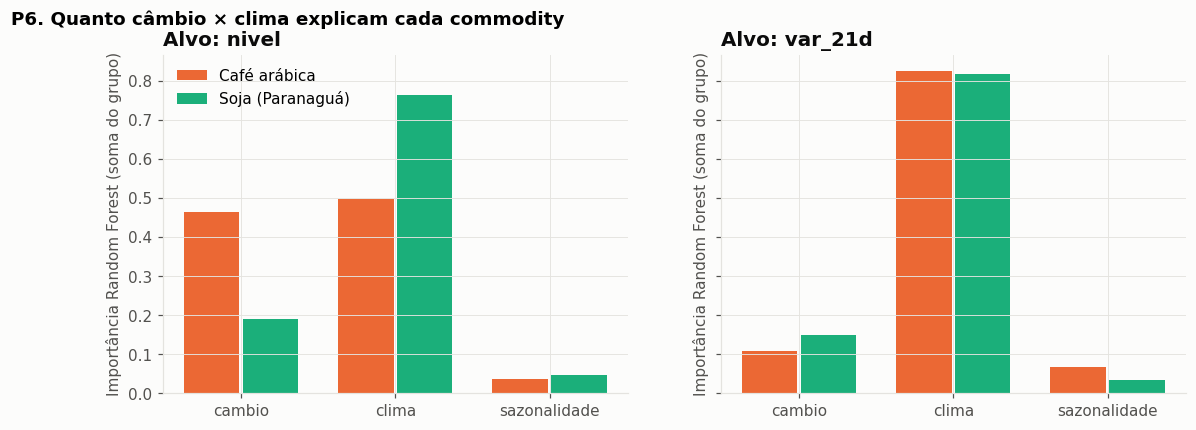

In [7]:
modelos.grafico_importancia_grupos(importancias);

In [8]:
importancias.groupby(["produto", "alvo", "grupo"])[["importancia_lr", "importancia_rf"]].sum().round(3)

importancia_lr  importancia_rf
produto alvo    grupo                                       
cafe    nivel   cambio                 0.178           0.465
                clima                  0.665           0.498
                sazonalidade           0.158           0.037
        var_21d cambio                 0.098           0.108
                clima                  0.754           0.826
                sazonalidade           0.148           0.066
soja    nivel   cambio                 0.106           0.191
                clima                  0.711           0.763
                sazonalidade           0.183           0.047
        var_21d cambio                 0.115           0.149
                clima                  0.728           0.817
                sazonalidade           0.157           0.035

### Interpretação
- R² fora da amostra baixo/negativo é esperado: preços de commodities mudam de patamar e modelos treinados no passado não extrapolam. Compare sempre com `baseline_media`.
- O que interessa é **qual grupo** (câmbio, clima, sazonalidade) concentra a importância em cada commodity.